# Nonimaging concentrators: the compound parabolic concentrator and the edge-ray principle

Notebook 83 showed that a lens cannot reach the concentration limit
$C_\max = n^2/\sin^2\alpha$. To get there, every point of the absorber has
to receive light from its whole hemisphere, $\mathrm{NA}' = n$, while the
lens's marginal ray stops well short of that. Lenses are built to image,
and imaging is more than concentration needs: a concentrator only has to
get every ray that enters within the acceptance angle $\theta_a$ to the
exit aperture, in any order and by any path.

The **edge-ray principle** (Welford and Winston) turns this into a design
rule. If the rays from the edge of the input phase space (the rim of the
entrance, at the angle $\pm\theta_a$) are sent to the edge of the output
phase space (the rim of the exit, at $\pm 90°$), everything in between
follows. In 2D the wall that does this is a parabola. Its axis is tilted by
$\theta_a$ against the axis of the concentrator, and its focus sits on the
opposite rim of the exit aperture, so that every ray entering at
$\theta_a$ is reflected onto that rim. Two such parabolic arcs make the
**compound parabolic concentrator** (CPC), with

$$a = \frac{a'}{\sin\theta_a}, \qquad L = \frac{a + a'}{\tan\theta_a},
\qquad C = \frac{a}{a'} = \frac{1}{\sin\theta_a}\ (\text{2D}),\quad
\left(\frac{a}{a'}\right)^2 = \frac{1}{\sin^2\theta_a}\ (\text{3D}).$$

The geometric concentration equals the limit of notebook 83. The 2D CPC
(a trough) is an ideal concentrator. The 3D CPC, a surface of revolution,
comes very close but rejects a few skew rays inside $\theta_a$ and lets a
few through beyond it.

`il.CPC` traces rays through hollow mirror CPCs and through solid dielectric
CPCs, which reflect by total internal reflection. It handles both 2D and
3D, and optionally truncates the CPC. The wall hit is bracketed along each
ray segment and refined by bisection; with numba installed
(`pip install pyoptics[fast]`) this runs in a compiled loop. The sections
below cover the edge rays (1), the transmission against angle in 2D and 3D
together with the étendue that comes out (2), skew rays (3), truncation (4),
dielectric CPCs and why the absorber must sit in optical contact (5), and a
CPC secondary behind the burning glass of notebook 83 (6).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import illumination as il
from pyoptics import sketch
from pyoptics import raytrace as rt

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(84)
ALPHA = il.SUN_ANGULAR_RADIUS

def draw_cpc(ax, cpc, **kw):
    z, r = cpc.profile()
    for s in (1, -1):
        ax.plot(z, s*r, color="k", lw=1.5, **kw)
    ax.plot([0, 0], [-r[0], r[0]], color=GREY, lw=0.8, ls=":")
    ax.plot([z[-1]]*2, [-r[-1], r[-1]], color=ORANGE, lw=3, solid_capstyle="butt")

## 1. Edge rays

A 2D CPC with $\theta_a = 20°$ and the exit half width $a' = 1$ mm, shown
with three fans of parallel rays:

- just inside $\theta_a$, where every ray, direct or reflected, arrives at
  the lower exit rim (the focus of the upper parabola) or close to it;
- at $0.6\,\theta_a$, where everything gets through;
- at $1.1\,\theta_a$, where everything is reflected back out of the
  entrance.

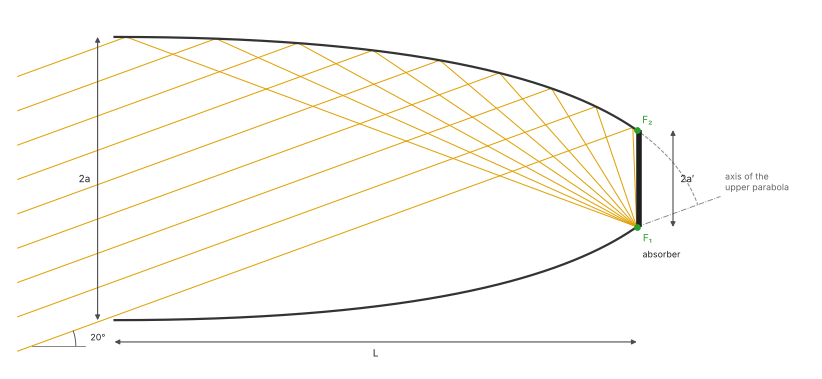

In [2]:
fig, ax = plt.subplots(figsize=(13, 6))
sketch.cpc_edge_rays(ax, acceptance=20.0)
plt.show()

In [3]:
TH1 = np.deg2rad(20)
cpc1 = il.CPC(TH1, 1.0, kind="2d")
print("2D CPC, theta = 20 deg: a' = 1, a = {:.4f} (1/sin = {:.4f}), L = {:.4f} ((a + a')/tan = {:.4f})"
      .format(cpc1.entrance_radius, 1/np.sin(TH1), cpc1.length, (cpc1.entrance_radius + 1)/np.tan(TH1)))
fans = {}
for name, ang in [("edge rays, θ = 0.999 θₐ", 0.999*TH1), ("θ = 0.6 θₐ", 0.6*TH1), ("θ = 1.1 θₐ", 1.1*TH1)]:
    x = np.linspace(-1, 1, 15)*cpc1.entrance_radius*0.999
    P = np.column_stack([x, 0*x, 0*x])
    d = np.tile([np.sin(ang), 0, np.cos(ang)], (len(x), 1))
    res, V = cpc1.trace(P, d, paths=True)
    fans[name] = (res, V)
    print("{:18s}: transmitted {}/{}".format(name, res.transmitted.sum(), len(x)))
# the edge rays end at the opposite exit rim:
res = fans["edge rays, θ = 0.999 θₐ"][0]
print("edge rays at the exit: x = {:.6f} ... {:.6f}".format(np.nanmin(res.points[:, 0]), np.nanmax(res.points[:, 0])))

2D CPC, theta = 20 deg: a' = 1, a = 2.9238 (1/sin = 2.9238), L = 10.7806 ((a + a')/tan = 10.7806)
edge rays, θ = 0.999 θₐ: transmitted 15/15
θ = 0.6 θₐ        : transmitted 15/15
θ = 1.1 θₐ        : transmitted 0/15
edge rays at the exit: x = -0.997794 ... 0.998663


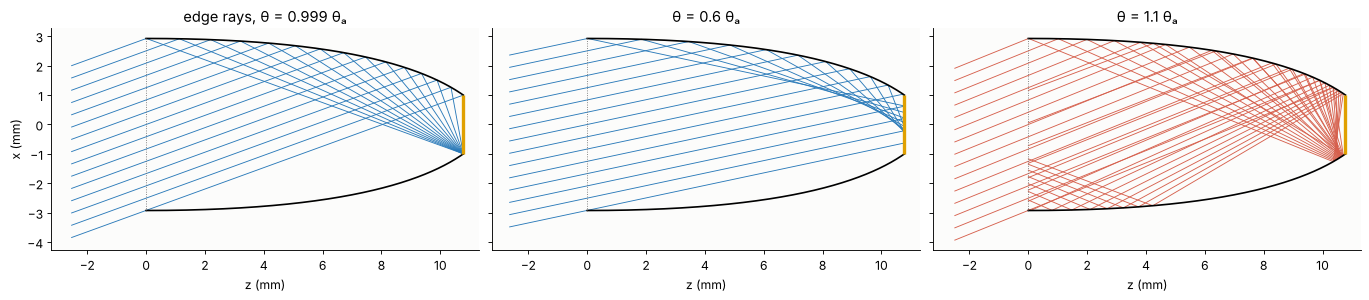

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained", sharey=True)
for a, (name, (res, V)) in zip(ax, fans.items()):
    for i in range(V.shape[1]):
        v = V[:, i]
        start = v[0] - 0.25*cpc1.length*np.array([np.sin(np.arctan2(*(v[1] - v[0])[[0, 2]])), 0,
                                                    np.cos(np.arctan2(*(v[1] - v[0])[[0, 2]]))])
        pts = np.vstack([start, v])
        a.plot(pts[:, 2], pts[:, 0], color=BLUE if res.transmitted[i] else RED, lw=0.8)
    draw_cpc(a, cpc1)
    a.set_title(name)
    a.set_xlabel("z (mm)")
    a.set_aspect("equal")
    a.set_xlim(-0.3*cpc1.length, 1.05*cpc1.length)
ax[0].set_ylabel("x (mm)")
plt.show()

The edge-ray fan converges onto the exit rim, which is where the parabola
focuses it, and the rays that miss the wall go straight to the other rim.
Beyond $\theta_a$ the rays bounce between the walls, turn round and leave
through the entrance: the CPC is a mirror funnel that rejects exactly what
it cannot concentrate.

## 2. Transmission against angle, and what comes out

We take a 2D and a 3D CPC with $\theta_a = 10°$, fill the entrance with
parallel rays at angles from 0 to 14°, and integrate the transmission
$T(\theta)$ over the projected solid angle. Normalized to the ideal, that
integral is the accepted étendue:
$\int T\,dp/(2\sin\theta_a)$ in 2D and
$\int T\,2p\,dp/\sin^2\theta_a$ in 3D. We then fill the entrance with
Lambertian light from the whole hemisphere. The transmitted power times the
étendue of the input can be at most the étendue of the exit aperture
($2\cdot 2a'$ in 2D, $\pi\cdot\pi a'^2$ in 3D), and an ideal concentrator
reaches it.

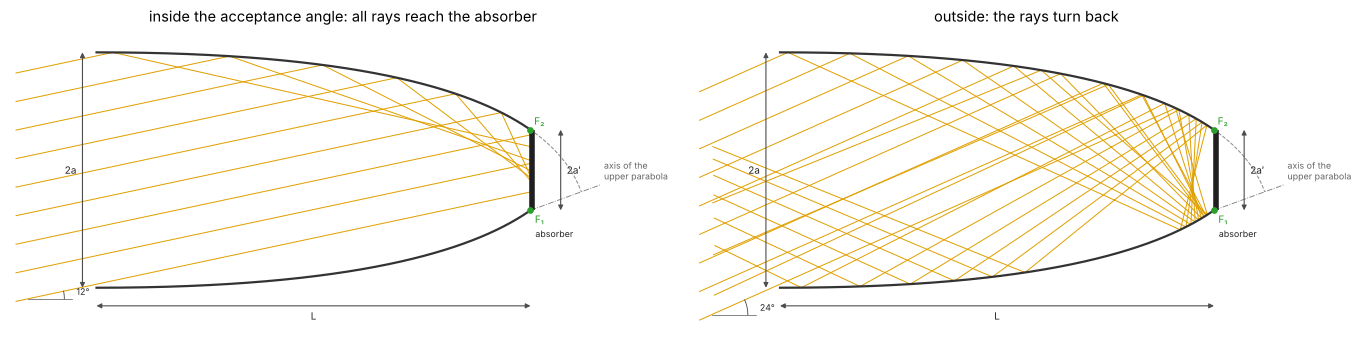

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.8), layout="constrained")
sketch.cpc_edge_rays(ax[0], acceptance=20.0, ray_angle=12.0, title="inside the acceptance angle: all rays reach the absorber")
sketch.cpc_edge_rays(ax[1], acceptance=20.0, ray_angle=24.0, title="outside: the rays turn back")
plt.show()

In [6]:
TH2 = np.deg2rad(10)
cpc2d = il.CPC(TH2, 1.0, kind="2d")
cpc3d = il.CPC(TH2, 1.0, kind="3d")
angles = np.deg2rad(np.linspace(0, 14, 57))
T2, T3, nref3 = [], [], []
for ang in angles:
    P, d = il.tilted_beam(20000, cpc2d.entrance_radius, ang, kind="2d", rng=rng)
    T2.append(cpc2d.trace(P, d).transmitted.mean())
    P, d = il.tilted_beam(20000, cpc3d.entrance_radius, ang, kind="3d", rng=rng)
    r3 = cpc3d.trace(P, d)
    T3.append(r3.transmitted.mean())
    nref3.append(r3.n_reflections[r3.transmitted].mean() if r3.transmitted.any() else np.nan)
T2, T3 = np.array(T2), np.array(T3)
# accepted étendue: integral of T over the projected solid angle, over pi sin^2(theta_a) (3D) or 2 sin(theta_a) (2D)
s = np.sin(angles)
acc3 = np.trapezoid(T3*2*s, s)/np.sin(TH2)**2
acc2 = np.trapezoid(T2, s)/np.sin(TH2)
print("accepted étendue / ideal: 2D {:.4f}, 3D {:.4f}".format(acc2, acc3))
print("3D CPC: T = {:.3f} at 0.9 theta_a, {:.3f} at theta_a, {:.3f} at 1.1 theta_a"
      .format(np.interp(0.9*TH2, angles, T3), np.interp(TH2, angles, T3), np.interp(1.1*TH2, angles, T3)))

# Lambertian light over the whole hemisphere at the entrance: what comes out?
N2 = 400_000
for cpc in (cpc2d, cpc3d):
    if cpc.kind == "2d":
        xs = (2*rng.random(N2) - 1)*cpc.entrance_radius
        P = np.column_stack([xs, 0*xs, 0*xs])
        d = il.directions_from_sines(2*rng.random(N2) - 1, 0*xs)
        G_in, G_out = il.etendue_2d(2*cpc.entrance_radius, 1.0), il.etendue_2d(2*cpc.exit_radius, 1.0)
    else:
        src = il.LambertianSource(cpc.entrance_radius, na=1.0)
        R = src.rays(N2, rng)
        P, d = R.points, R.directions
        G_in, G_out = src.etendue, il.etendue_lambertian(np.pi*cpc.exit_radius**2, 1.0)
    res = cpc.trace(P, d)
    print("{} CPC, Lambertian hemisphere at the entrance: transmitted {:.4f}, times G_in = {:.3f}, G_exit = {:.3f}"
          .format(cpc.kind, res.transmitted.mean(), res.transmitted.mean()*G_in, G_out))
    if cpc.kind == "2d":
        res2d_lamb, p_in2d = res, d[:, 0]

accepted étendue / ideal: 2D 0.9988, 3D 0.9992
3D CPC: T = 0.934 at 0.9 theta_a, 0.483 at theta_a, 0.053 at 1.1 theta_a


2d CPC, Lambertian hemisphere at the entrance: transmitted 0.1745, times G_in = 4.019, G_exit = 4.000


3d CPC, Lambertian hemisphere at the entrance: transmitted 0.0304, times G_in = 9.952, G_exit = 9.870


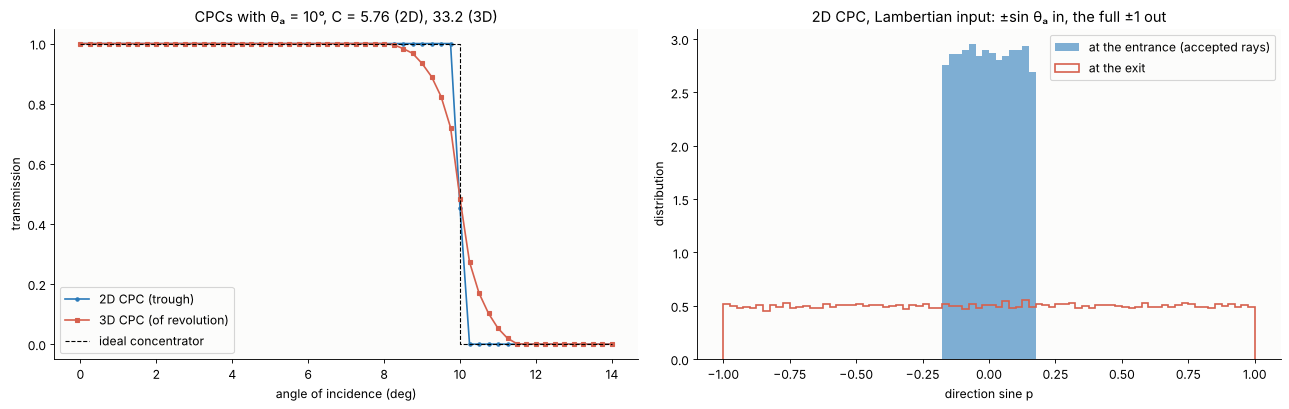

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
ax[0].plot(np.rad2deg(angles), T2, "o-", color=BLUE, ms=3, label="2D CPC (trough)")
ax[0].plot(np.rad2deg(angles), T3, "s-", color=RED, ms=3, label="3D CPC (of revolution)")
ax[0].plot([0, 10, 10, 14], [1, 1, 0, 0], "--", color="k", lw=1, label="ideal concentrator")
ax[0].set_xlabel("angle of incidence (deg)")
ax[0].set_ylabel("transmission")
ax[0].set_title("CPCs with θₐ = 10°, C = {:.2f} (2D), {:.1f} (3D)".format(cpc2d.geometric_concentration,
                                                                          cpc3d.geometric_concentration))
ax[0].legend()
p_exit = res2d_lamb.directions[res2d_lamb.transmitted, 0]
ax[1].hist(p_in2d[res2d_lamb.transmitted], bins=80, range=(-1, 1), density=True, color=BLUE, alpha=0.6,
           label="at the entrance (accepted rays)")
ax[1].hist(p_exit, bins=80, range=(-1, 1), density=True, histtype="step", color=RED, lw=1.5,
           label="at the exit")
ax[1].set_xlabel("direction sine p")
ax[1].set_ylabel("distribution")
ax[1].set_title("2D CPC, Lambertian input: ±sin θₐ in, the full ±1 out")
ax[1].legend()
plt.show()

The 2D CPC is an ideal step to the sampling of the angles: it accepts
99.9 % of the ideal étendue. The 3D CPC's transition is spread over about
±1° around $\theta_a$, with 93 % transmission at $0.9\,\theta_a$ and 5 % at
$1.1\,\theta_a$, as in Welford and Winston's ray traces. What it rejects
inside it makes up for outside, so it still accepts 99.9 % of the ideal
étendue. For Lambertian light from the whole hemisphere, the transmitted
fraction is $\sin\theta_a$ (2D, 0.1745) or $\sin^2\theta_a$ (3D, 0.0304),
and the transmitted étendue equals that of the exit aperture to the Monte
Carlo noise: a CPC fills its exit as completely as the second law permits.

The right panel shows the 2D case in phase space. The accepted rays occupy
$|p| \le \sin\theta_a$ at the entrance and come out spread uniformly over
the whole $|p| \le 1$. The CPC trades position for angle, exactly the
rectangle-to-rectangle map that étendue conservation allows.

## 3. Skew rays: why the 3D CPC is not ideal

A ray entering a CPC of revolution at the polar angle $\theta$ and the
radius $\rho$ carries the skew invariant $h = \rho\,\sin\theta\sin\psi$,
where $\psi$ is the angle between its azimuth and the radius vector.
Reflection at a surface of revolution conserves $h$ (notebook 83), and
the parabola was designed for meridional rays ($h = 0$) only. We trace
100,000 rays per angle between 8° and 12° and sort them by
$h/(a\sin\theta)$ (in $[-1, 1]$).

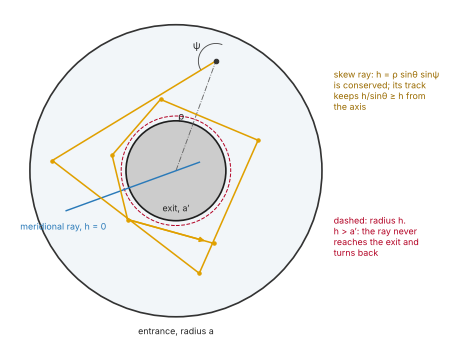

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sketch.cpc_skew_ray(ax, acceptance=20.0)
plt.show()

In [9]:
N3 = 100_000
ang3 = np.deg2rad(np.linspace(8, 12, 17))
H3, T3s = [], []
for ang in ang3:
    P, d = il.tilted_beam(N3, cpc3d.entrance_radius, ang, azimuth=0.0, kind="3d", rng=rng)
    res = cpc3d.trace(P, d)
    h = il.skew_invariant(P, d)/(cpc3d.entrance_radius*np.sin(ang))   # -1 ... 1
    H3.append(h)
    T3s.append(res.transmitted)
hb = np.linspace(-1, 1, 41)
Tmap = np.array([[t[(h >= lo) & (h < hi)].mean() for lo, hi in zip(hb[:-1], hb[1:])] for h, t in zip(H3, T3s)])

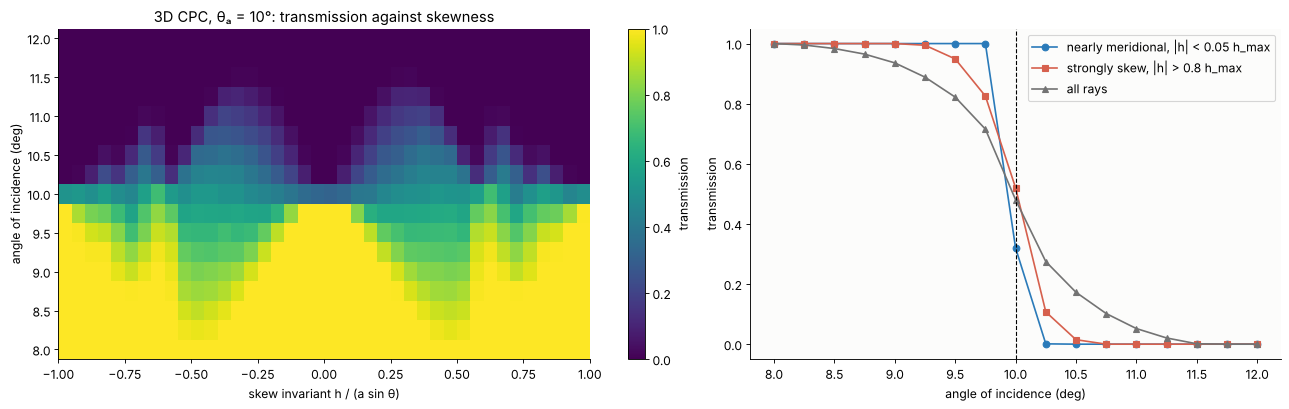

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
da = np.rad2deg(ang3[1] - ang3[0])
im = ax[0].pcolormesh(hb, np.r_[np.rad2deg(ang3) - da/2, np.rad2deg(ang3[-1]) + da/2], Tmap, cmap="viridis",
                      vmin=0, vmax=1, shading="flat")
ax[0].set_xlabel("skew invariant h / (a sin θ)")
ax[0].set_ylabel("angle of incidence (deg)")
ax[0].set_title("3D CPC, θₐ = 10°: transmission against skewness")
fig.colorbar(im, ax=ax[0], label="transmission")
mer = [t[np.abs(h) < 0.05].mean() for h, t in zip(H3, T3s)]
skw = [t[np.abs(h) > 0.8].mean() for h, t in zip(H3, T3s)]
ax[1].plot(np.rad2deg(ang3), mer, "o-", color=BLUE, label="nearly meridional, |h| < 0.05 h_max")
ax[1].plot(np.rad2deg(ang3), skw, "s-", color=RED, label="strongly skew, |h| > 0.8 h_max")
ax[1].plot(np.rad2deg(ang3), [t.mean() for t in T3s], "^-", color=GREY, label="all rays")
ax[1].axvline(10, color="k", ls="--", lw=1)
ax[1].set_xlabel("angle of incidence (deg)")
ax[1].set_ylabel("transmission")
ax[1].legend()
plt.show()

Nearly meridional rays behave like rays in the 2D CPC and switch off sharply
at $\theta_a$; the residual width is set by the 0.25° steps. The losses
inside $\theta_a$ and the gains outside come from skew rays. The rejection
inside is concentrated at moderate skewness, $|h| \approx 0.3$ to
$0.6\,h_\max$, and the acceptance outside at similar values; the most
skew rays, which spiral along the wall, behave nearly ideally. This is the
residual of the edge-ray design in 3D. Ideal 3D concentrators exist
(Winston's flow-line designs, Miñano's), but not as a single surface of
revolution with mirror walls.

## 4. Truncation

A full CPC for small $\theta_a$ is long, $L/a' \approx 1/\sin\theta_a\tan\theta_a$,
and its top part is nearly parallel to the axis: it reflects few rays and
adds little. Practical CPCs (solar collectors, light cones in front of
detectors) are cut at a smaller entrance radius. We truncate the
$\theta_a = 10°$ CPC at entrance radii between 1.5 and 5.76 mm, and for
each one compute the geometric concentration, the transmission of
Lambertian light within $\theta_a$, and the transmission against angle.

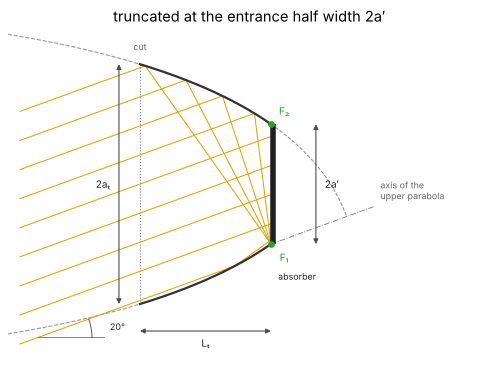

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sketch.cpc_edge_rays(ax, acceptance=20.0, truncation=2.0, title="truncated at the entrance half width 2a′")
plt.show()

In [12]:
TH4 = np.deg2rad(10)
full = il.CPC(TH4, 1.0, kind="3d")
cuts = np.linspace(1.5, full.entrance_radius, 12)
rows = []
for a_t in cuts:
    c = full if np.isclose(a_t, full.entrance_radius) else il.CPC(TH4, 1.0, kind="3d", truncation=a_t)
    P, d = il.tilted_beam(20000, c.entrance_radius, 0.95*TH4, kind="3d", rng=rng)
    T_in = c.trace(P, d).transmitted.mean()
    P, d = il.tilted_beam(20000, c.entrance_radius, 1.3*TH4, kind="3d", rng=rng)
    T_out = c.trace(P, d).transmitted.mean()
    src = il.LambertianSource(c.entrance_radius, na=np.sin(TH4))
    R = src.rays(100_000, rng)
    res = c.trace(R.points, R.directions)
    rows.append((a_t, c.length, c.geometric_concentration, T_in, T_out, res.transmitted.mean(),
                 res.n_reflections[res.transmitted].mean()))
rows = np.array(rows)
ang4 = np.deg2rad(np.linspace(0, 20, 81))
T4 = {}
for a_t in (full.entrance_radius, 4.21, 3.05):
    c = full if a_t == full.entrance_radius else il.CPC(TH4, 1.0, kind="3d", truncation=a_t)
    T = []
    for ang in ang4:
        P, d = il.tilted_beam(10000, c.entrance_radius, ang, kind="3d", rng=rng)
        T.append(c.trace(P, d).transmitted.mean())
    T4[a_t] = (c, np.array(T))
for a_t, L, C, Ti, To, Tl, nr in rows:
    print("a = {:5.2f}: L = {:6.2f} ({:4.0%}), C_geo = {:5.1f}, T(0.95 th) = {:.3f}, T(1.3 th) = {:.3f}, "
          "Lambertian within th: {:.3f}, reflections {:.2f}".format(a_t, L, L/full.length, C, Ti, To, Tl, nr))

a =  1.50: L =   0.69 (  2%), C_geo =   2.2, T(0.95 th) = 1.000, T(1.3 th) = 0.833, Lambertian within th: 1.000, reflections 0.56
a =  1.89: L =   1.37 (  4%), C_geo =   3.6, T(0.95 th) = 1.000, T(1.3 th) = 0.770, Lambertian within th: 1.000, reflections 0.72
a =  2.27: L =   2.20 (  6%), C_geo =   5.2, T(0.95 th) = 1.000, T(1.3 th) = 0.715, Lambertian within th: 1.000, reflections 0.81
a =  2.66: L =   3.20 (  8%), C_geo =   7.1, T(0.95 th) = 1.000, T(1.3 th) = 0.652, Lambertian within th: 1.000, reflections 0.86
a =  3.05: L =   4.41 ( 11%), C_geo =   9.3, T(0.95 th) = 1.000, T(1.3 th) = 0.568, Lambertian within th: 1.000, reflections 0.89
a =  3.44: L =   5.87 ( 15%), C_geo =  11.8, T(0.95 th) = 0.995, T(1.3 th) = 0.499, Lambertian within th: 0.999, reflections 0.95
a =  3.82: L =   7.65 ( 20%), C_geo =  14.6, T(0.95 th) = 0.956, T(1.3 th) = 0.430, Lambertian within th: 0.990, reflections 1.03
a =  4.21: L =   9.85 ( 26%), C_geo =  17.7, T(0.95 th) = 0.912, T(1.3 th) = 0.362, Lamber

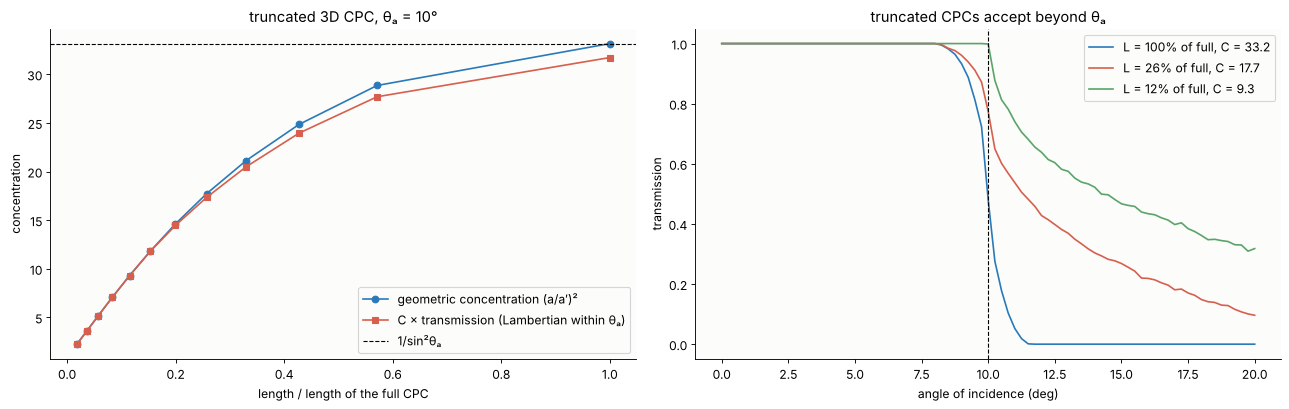

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
ax[0].plot(rows[:, 1]/full.length, rows[:, 2], "o-", color=BLUE, label="geometric concentration (a/a′)²")
ax[0].plot(rows[:, 1]/full.length, rows[:, 2]*rows[:, 5], "s-", color=RED, label="C × transmission (Lambertian within θₐ)")
ax[0].axhline(1/np.sin(TH4)**2, color="k", ls="--", lw=1, label="1/sin²θₐ")
ax[0].set_xlabel("length / length of the full CPC")
ax[0].set_ylabel("concentration")
ax[0].set_title("truncated 3D CPC, θₐ = 10°")
ax[0].legend()
for (a_t, (c, T)), col in zip(T4.items(), (BLUE, RED, GREEN)):
    ax[1].plot(np.rad2deg(ang4), T, color=col, lw=1.5,
               label="L = {:.0%} of full, C = {:.1f}".format(c.length/full.length, c.geometric_concentration))
ax[1].axvline(10, color="k", ls="--", lw=1)
ax[1].set_xlabel("angle of incidence (deg)")
ax[1].set_ylabel("transmission")
ax[1].set_title("truncated CPCs accept beyond θₐ")
ax[1].legend()
plt.show()

Cutting the CPC to 57 % of its length keeps 87 % of the concentration
(28.9 of 33.2). Halving the concentration needs only a quarter of the
length. Every truncated CPC transmits nearly all the light within
$\theta_a$, about one reflection on average, but also lets through much of
the light beyond it: a truncated CPC accepts more étendue than it can
concentrate, so its concentration is below $1/\sin^2\theta_a$ for its
length. For a solar collector that is often the right trade, because
diffuse sky light outside $\theta_a$ is still useful.

## 5. Dielectric CPCs: TIR walls and optical contact

A CPC filled with glass of index $n$ refracts the incoming light at its flat
entrance to $\theta' = \arcsin(\sin\theta_a/n)$ and is designed for that
angle. It concentrates by $n^2/\sin^2\theta_a$, $n^2$ times more than a
hollow CPC with the same acceptance. This is the limit for an absorber in
glass, since the basic radiance $L/n^2$ is what is conserved. Its walls
work by total internal reflection, free of mirror losses, as long as the
rays meet them beyond the critical angle. We compare a hollow and an
$n = 1.5$ CPC, both with $\theta_a = 30°$ in air and $a' = 1$ mm. The
dielectric CPC's exit is first taken in optical contact with an absorber
of the same index, then left open to air.

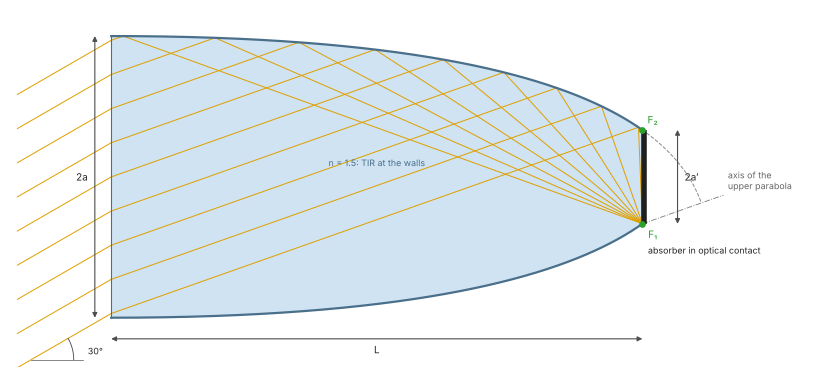

In [14]:
fig, ax = plt.subplots(figsize=(13, 6))
sketch.cpc_edge_rays(ax, acceptance=30.0, n=1.5)
plt.show()

In [15]:
TH5 = np.deg2rad(30)
N_D = 1.5
diel = il.CPC(TH5, 1.0, n=N_D, kind="3d")
hollow = il.CPC(TH5, 1.0, kind="3d")
print("dielectric CPC: design angle inside {:.2f} deg, a = {:.3f}, L = {:.3f}, C_geo = {:.2f} (n^2/sin^2 = {:.2f})"
      .format(np.rad2deg(diel.design_angle), diel.entrance_radius, diel.length, diel.geometric_concentration,
              N_D**2/np.sin(TH5)**2))
print("hollow CPC: a = {:.3f}, L = {:.3f}, C_geo = {:.2f}".format(hollow.entrance_radius, hollow.length,
                                                              hollow.geometric_concentration))
ang5 = np.deg2rad(np.linspace(0, 40, 41))
fates = {}
T5h, T5d, T5air = [], [], []
for ang in ang5:
    P, d = il.tilted_beam(20000, diel.entrance_radius, ang, kind="3d", rng=rng)
    r = diel.trace(P, d)
    T5d.append(r.transmitted.mean())
    fates[ang] = np.bincount(r.fate, minlength=6)/len(P)
    T5air.append(diel.trace(P, d, n_out=1.0).transmitted.mean())
    P, d = il.tilted_beam(20000, hollow.entrance_radius, ang, kind="3d", rng=rng)
    T5h.append(hollow.trace(P, d).transmitted.mean())
T5h, T5d, T5air = map(np.array, (T5h, T5d, T5air))
for ang in ang5[::5]:
    print("dielectric CPC at {:4.1f} deg: transmitted {:.4f}, through the walls (TIR failed) {:.4f}, turned back {:.4f}"
          .format(np.rad2deg(ang), fates[ang][0], fates[ang][2], fates[ang][1]))
R5 = il.LambertianSource(diel.entrance_radius, na=np.sin(TH5)).rays(400_000, rng)
eta_glass = diel.trace(R5.points, R5.directions).transmitted.mean()
eta_air = diel.trace(R5.points, R5.directions, n_out=1.0).transmitted.mean()
print("Lambertian light within theta_a: into an absorber in contact {:.3f}, into air {:.3f} (bound 1/n^2 = {:.3f} of the ideal)"
      .format(eta_glass, eta_air, 1/N_D**2))
print("into air instead of an optically contacted absorber: T at 0 deg {:.3f}, at 20 deg {:.3f}"
      .format(T5air[0], np.interp(np.deg2rad(20), ang5, T5air)))

dielectric CPC: design angle inside 19.47 deg, a = 3.000, L = 11.314, C_geo = 9.00 (n^2/sin^2 = 9.00)
hollow CPC: a = 2.000, L = 5.196, C_geo = 4.00


dielectric CPC at  0.0 deg: transmitted 1.0000, through the walls (TIR failed) 0.0000, turned back 0.0000
dielectric CPC at  5.0 deg: transmitted 1.0000, through the walls (TIR failed) 0.0000, turned back 0.0000
dielectric CPC at 10.0 deg: transmitted 1.0000, through the walls (TIR failed) 0.0000, turned back 0.0000
dielectric CPC at 15.0 deg: transmitted 1.0000, through the walls (TIR failed) 0.0000, turned back 0.0000
dielectric CPC at 20.0 deg: transmitted 0.9999, through the walls (TIR failed) 0.0001, turned back 0.0000
dielectric CPC at 25.0 deg: transmitted 0.9932, through the walls (TIR failed) 0.0068, turned back 0.0000
dielectric CPC at 30.0 deg: transmitted 0.4520, through the walls (TIR failed) 0.4114, turned back 0.1366
dielectric CPC at 35.0 deg: transmitted 0.0000, through the walls (TIR failed) 0.7337, turned back 0.2663
dielectric CPC at 40.0 deg: transmitted 0.0000, through the walls (TIR failed) 0.7391, turned back 0.2609


Lambertian light within theta_a: into an absorber in contact 0.960, into air 0.442 (bound 1/n^2 = 0.444 of the ideal)
into air instead of an optically contacted absorber: T at 0 deg 0.681, at 20 deg 0.498


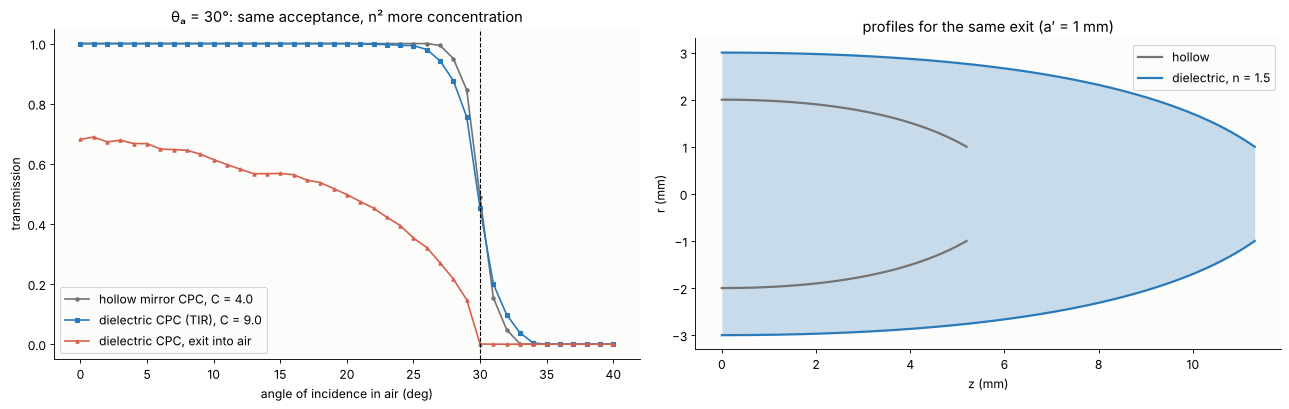

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
ax[0].plot(np.rad2deg(ang5), T5h, "o-", color=GREY, ms=3, label="hollow mirror CPC, C = {:.1f}".format(hollow.geometric_concentration))
ax[0].plot(np.rad2deg(ang5), T5d, "s-", color=BLUE, ms=3, label="dielectric CPC (TIR), C = {:.1f}".format(diel.geometric_concentration))
ax[0].plot(np.rad2deg(ang5), T5air, "^-", color=RED, ms=3, label="dielectric CPC, exit into air")
ax[0].axvline(30, color="k", ls="--", lw=1)
ax[0].set_xlabel("angle of incidence in air (deg)")
ax[0].set_ylabel("transmission")
ax[0].set_title("θₐ = 30°: same acceptance, n² more concentration")
ax[0].legend()
z, r = diel.profile()
zh, rh = hollow.profile()
for s in (1, -1):
    ax[1].plot(zh, s*rh, color=GREY, lw=2, label="hollow" if s == 1 else None)
    ax[1].fill_between(z, s*r, 0, color=BLUE, alpha=0.25, lw=0)
    ax[1].plot(z, s*r, color=BLUE, lw=2, label="dielectric, n = 1.5" if s == 1 else None)
ax[1].set_aspect("equal")
ax[1].set_xlabel("z (mm)")
ax[1].set_ylabel("r (mm)")
ax[1].set_title("profiles for the same exit (a′ = 1 mm)")
ax[1].legend()
plt.show()

The dielectric CPC is 1.5 times wider and 2.2 times longer than the hollow one for
the same exit and concentrates 9 instead of 4 times. TIR holds for every
ray up to 20° and loses 0.7 % at 25°. Only near the acceptance angle do
rays reach the walls close to the exit too steeply and escape. Mirror
coating the last part of the wall fixes this (`mirror=True` for a fully
mirrored dielectric CPC).

If the absorber is not in optical contact, the light must leave the glass
into air, where the exit aperture can carry only $\pi\cdot\pi a'^2$, i.e.
$1/n^2$ of the concentrated étendue. Everything else is totally reflected
at the exit face and turned back. For Lambertian input within $\theta_a$
the Monte Carlo gives 0.442 of the ideal against the bound
$1/n^2 = 0.444$. The extra $n^2$ concentration exists only inside the
glass; solar cells and detectors behind dielectric concentrators are
glued on for this reason.

## 6. A CPC secondary behind a burning glass

A CPC for sunlight alone would need $\theta_a = 0.27°$: for a 1 mm
absorber it would be 215 mm wide and 23 m long. Real solar furnaces
therefore pair an imaging primary (a dish, a heliostat field or a lens)
with a CPC secondary at its focus. The secondary's acceptance angle is the
largest ray angle of the primary, 33° for the f/0.5 hyperbolic lens of
notebook 83, and its entrance captures a chosen fraction of the light in
the focal plane. We trace a million solar rays through the lens and then
through hollow and dielectric secondaries. We compare their concentration
with the bare focus (an absorber that captures the same fraction) and
with the limit.

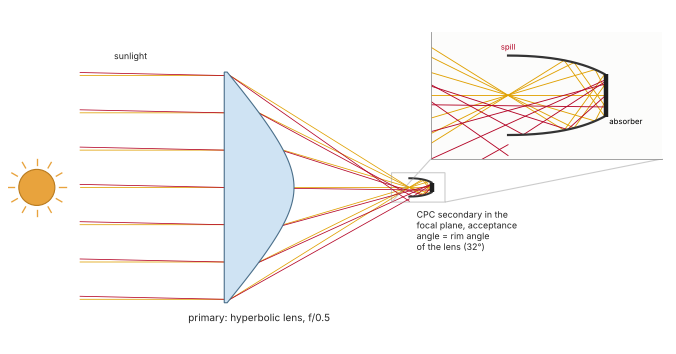

In [17]:
fig, ax = plt.subplots(figsize=(13, 5.5))
sketch.cpc_secondary(ax)
plt.show()

In [18]:
F, A6, N_LENS = 50.0, 50.0, 1.5
def hyperbolic_lens(a, f=F, n=N_LENS):
    """Plano-convex lens, flat side to the light, hyperbolic back (K = -n^2): stigmatic on axis."""
    R, K = -(n - 1)*f, -n**2
    c = 1/R
    sag = c*a**2/(1 + np.sqrt(1 - (1 + K)*c**2*a**2))
    return rt.System([rt.Surface(np.inf, abs(sag) + 2.0, n_after=n, semi_diameter=a),
                      rt.Surface(R, f, n_after=1.0, conic=K)], 0, 550e-6)

lens = hyperbolic_lens(A6)
R6 = il.LambertianSource(A6, na=np.sin(ALPHA), z=-1.0).rays(1_000_000, rng)
B6 = lens.trace(R6)
Q6, e6 = lens.to_image_frame(B6.points[-1], B6.directions[-1])
r6 = np.hypot(Q6[:, 0], Q6[:, 1])
na_max = np.nanmax(np.hypot(e6[:, 0], e6[:, 1]))
th_sec = np.arcsin(na_max)
print("lens f/0.5: largest ray angle at the focus {:.2f} deg (NA {:.3f})".format(np.rad2deg(th_sec), na_max))
C_max = il.concentration_limit(ALPHA)
results = []
for capture in (0.9, 0.95, 0.99):
    a_in = np.quantile(r6[np.isfinite(r6)], capture)
    bare = capture*A6**2/a_in**2
    for n_sec in (1.0, 1.5):
        sec = il.CPC(th_sec, a_in*np.sin(th_sec)/n_sec, n=n_sec, kind="3d")
        res = sec.trace(Q6, e6)
        eta = np.sum(res.transmitted)/len(Q6)
        C = eta*A6**2/sec.exit_radius**2
        results.append((capture, n_sec, a_in, bare, sec.exit_radius, sec.length, eta, C))
        dilution = (a_in*np.sin(th_sec))**2/(A6*np.sin(ALPHA))**2
        print("capture {:.0%}: bare absorber r = {:.3f} mm, C = {:5.0f} | CPC secondary n = {}: a = {:.3f}, a' = {:.3f}, "
              "L = {:.2f} mm, transmitted {:.3f}, C = {:6.0f} ({:.0%} of n^2 C_max)"
              .format(capture, a_in, bare, n_sec, sec.entrance_radius, sec.exit_radius, sec.length, eta, C,
                      C/(n_sec**2*C_max)))
        print("    étendue dilution at the CPC entrance {:.2f}: transmitted/dilution = {:.3f}".format(dilution, eta/dilution))

lens f/0.5: largest ray angle at the focus 32.98 deg (NA 0.544)


capture 90%: bare absorber r = 0.705 mm, C =  4532 | CPC secondary n = 1.0: a = 0.705, a' = 0.384, L = 1.68 mm, transmitted 0.878, C =  14922 (32% of n^2 C_max)
    étendue dilution at the CPC entrance 2.72: transmitted/dilution = 0.323


capture 90%: bare absorber r = 0.705 mm, C =  4532 | CPC secondary n = 1.5: a = 0.705, a' = 0.256, L = 2.47 mm, transmitted 0.839, C =  32086 (31% of n^2 C_max)
    étendue dilution at the CPC entrance 2.72: transmitted/dilution = 0.309


capture 95%: bare absorber r = 0.830 mm, C =  3448 | CPC secondary n = 1.0: a = 0.830, a' = 0.452, L = 1.98 mm, transmitted 0.929, C =  11379 (25% of n^2 C_max)
    étendue dilution at the CPC entrance 3.77: transmitted/dilution = 0.246


capture 95%: bare absorber r = 0.830 mm, C =  3448 | CPC secondary n = 1.5: a = 0.830, a' = 0.301, L = 2.90 mm, transmitted 0.881, C =  24278 (23% of n^2 C_max)
    étendue dilution at the CPC entrance 3.77: transmitted/dilution = 0.234


capture 99%: bare absorber r = 1.030 mm, C =  2334 | CPC secondary n = 1.0: a = 1.030, a' = 0.561, L = 2.45 mm, transmitted 0.974, C =   7749 (17% of n^2 C_max)
    étendue dilution at the CPC entrance 5.81: transmitted/dilution = 0.168


capture 99%: bare absorber r = 1.030 mm, C =  2334 | CPC secondary n = 1.5: a = 1.030, a' = 0.374, L = 3.60 mm, transmitted 0.928, C =  16616 (16% of n^2 C_max)
    étendue dilution at the CPC entrance 5.81: transmitted/dilution = 0.160


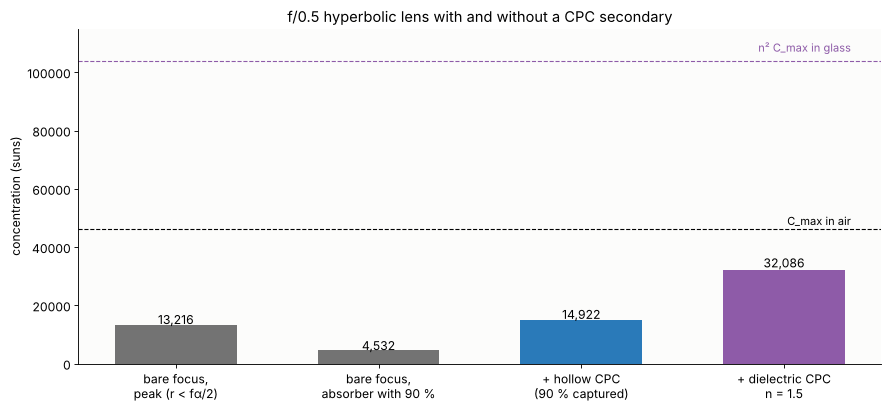

In [19]:
res90 = [r for r in results if r[0] == 0.9]
peak = np.mean(r6 < 0.5*F*ALPHA)*A6**2/(0.5*F*ALPHA)**2
labels = ["bare focus,\npeak (r < fα/2)", "bare focus,\nabsorber with 90 %", "+ hollow CPC\n(90 % captured)",
          "+ dielectric CPC\nn = 1.5"]
values = [peak, res90[0][3], res90[0][7], res90[1][7]]
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
bars = ax.bar(labels, values, color=[GREY, GREY, BLUE, PURPLE], width=0.6)
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v*1.03, "{:,.0f}".format(v), ha="center", fontsize=11)
ax.axhline(C_max, color="k", ls="--", lw=1)
ax.text(3.33, C_max*1.03, "C_max in air", ha="right", fontsize=10)
ax.axhline(N_LENS**2*C_max, color=PURPLE, ls="--", lw=1)
ax.text(3.33, N_LENS**2*C_max*1.03, "n² C_max in glass", ha="right", fontsize=10, color=PURPLE)
ax.set_ylim(0, 115000)
ax.set_ylabel("concentration (suns)")
ax.set_title("f/0.5 hyperbolic lens with and without a CPC secondary")
plt.show()

The secondary multiplies the concentration on a 90 % absorber by 3.3, from
4500 to 14,900 suns. Filled with glass, it reaches 32,000 suns, more
than the peak of the bare lens. It still stays at a third of the limit, and
the reason is exact. At the CPC entrance the light occupies only part of
the phase space the CPC accepts: radius $a$ times angle $\theta_a$ is 2.7
times the étendue of the sunlight collected by the lens,
$\pi^2 (50\text{ mm}\cdot\sin\alpha)^2$. The lens's coma spreads off-axis
points over the entrance without filling all directions at each point.
The CPC cannot undo this dilution, and the printed check
$C/(n^2 C_\max) = \eta/\text{dilution}$ holds to 1 %. Capturing more light
needs a larger entrance and dilutes more (5.8 for 99 %).

Reaching $C_\max$ needs a primary that keeps the étendue compact, one that
obeys the sine condition, so that its focal spot is uniformly filled with
all directions up to its NA, or a secondary tailored to the actual phase
space of the primary instead of a plain CPC. The experiments that brought
sunlight to the radiance of the solar surface (Gleckman, O'Gallagher and
Winston 1989; Cooke et al. 1990) used a long focal length primary with
little dilution and a dielectric secondary with the absorber in optical
contact.

## Summary

- **Edge-ray principle:** sending the edge of the input phase space to the
  edge of the output gives the CPC: tilted parabolas with their foci on
  the opposite exit rims, $a = a'/\sin\theta_a$,
  $L = (a + a')/\tan\theta_a$ (`il.cpc_profile()`, `il.CPC`). The edge
  rays converge onto the exit rim in the trace.
- **Ideal in 2D, nearly ideal in 3D:** the trough's transmission is a step
  at $\theta_a$. The CPC of revolution blurs it over ±1° but still accepts
  99.9 % of the ideal étendue, and both fill their exit aperture with
  exactly the exit étendue ($2\cdot 2a'$, $\pi^2a'^2$) under Lambertian
  input. The 2D CPC maps $|p| \le \sin\theta_a$ onto $|p| \le 1$.
- **Skew rays:** rejection inside $\theta_a$ and acceptance outside it come
  from moderately skew rays; meridional rays switch off sharply.
- **Truncation:** 57 % of the length keeps 87 % of the concentration.
  Truncated CPCs accept light beyond $\theta_a$.
- **Dielectric CPCs:** $n^2/\sin^2\theta_a$ with TIR walls (losses only
  within a few degrees of $\theta_a$ at $\theta_a = 30°$). Without optical
  contact only $1/n^2$ of the light leaves the exit (0.442 against 0.444).
- **Secondary concentrators:** behind an f/0.5 hyperbolic lens a CPC
  raises the concentration on a 90 % absorber from 4500 to 14,900 suns
  (32,000 suns in glass). The rest of the gap to $C_\max$ is the étendue
  dilution by the lens's coma, and $C/(n^2C_\max) = \eta/\text{dilution}$
  holds.

In [20]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 36 s


## References

- R. Winston, "Principles of solar concentrators of a novel design", Solar Energy 16, 89-95 (1974).
- W. T. Welford and R. Winston, *High Collection Nonimaging Optics*, Academic Press (1989), ch. 4 (the CPC, transmission-angle curves of 3D CPCs, truncation) and ch. 5 (dielectric CPCs).
- R. Winston, J. C. Miñano and P. Benítez, *Nonimaging Optics*, Elsevier (2005), ch. 4 and 5.
- J. Chaves, *Introduction to Nonimaging Optics*, 2nd ed., CRC Press (2016), ch. 2 and 3.
- A. Rabl, "Optical and thermal properties of compound parabolic concentrators", Solar Energy 18, 497-511 (1976).
- P. Gleckman, J. O'Gallagher and R. Winston, "Concentration of sunlight to solar-surface levels using non-imaging optics", Nature 339, 198-200 (1989).
- D. Cooke, P. Gleckman, H. Krebs, J. O'Gallagher, D. Sagie and R. Winston, "Brighter than the Sun", Nature 346, 802 (1990).